# Dimensionamento de equipe a partir da previsão por hora

> **Equipe, tempo de atendimento, folga e metas são fictícios** (cenário didático de WFM). O NYC 311 fornece só as chegadas. Todos os números abaixo vêm de `results/` (gerado por `scripts/run_all.py`).

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
R = json.loads((ROOT/'results'/'results.json').read_text(encoding='utf-8'))
TZ = 'America/New_York'
h = pd.read_parquet(ROOT/'data'/'processed'/'hourly.parquet')
idx = pd.DatetimeIndex(h['hour_ts']); idx = idx.tz_localize('UTC') if idx.tz is None else idx
s = pd.Series(h['calls'].to_numpy(), index=idx)
cmp_ = pd.read_parquet(ROOT/'results'/'previsto_realizado.parquet')
plan = pd.read_parquet(ROOT/'results'/'plano_pessoas.parquet')
R['data']

{'fonte': 'NYC 311 Service Requests (NYC Open Data), canal PHONE',
 'treino': 2024,
 'teste': 2025,
 'rows_in': 2037631,
 'null_ts': 0,
 'duplicates': 0,
 'other_channel': 0,
 'n_hours': 17544,
 'total_calls': 2037631,
 'horas_na_serie': 17544,
 'chamadas_na_serie': 2037631}

## 1. A série: chamadas de telefone por hora
Sazonalidade por hora do dia e dia da semana (horário de Nova York).

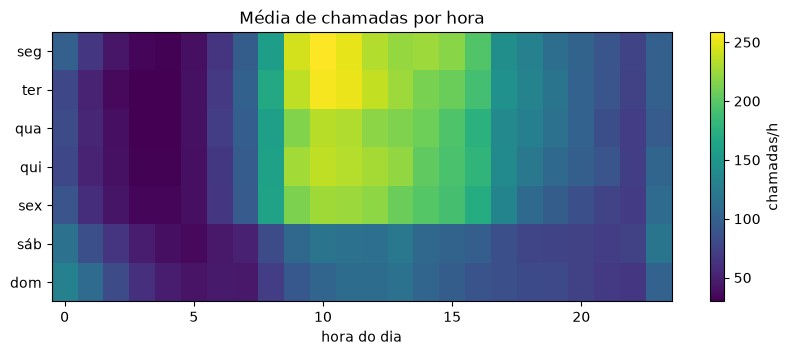

In [2]:
loc = s.index.tz_convert(TZ)
pivot = s.groupby([loc.day_of_week, loc.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis')
ax.set_yticks(range(7), ['seg','ter','qua','qui','sex','sáb','dom']); ax.set_xlabel('hora do dia'); ax.set_title('Média de chamadas por hora')
fig.colorbar(im, label='chamadas/h'); plt.show()

## 2. Previsto × realizado no ano de teste
Modelo de Poisson reajustado todo mês com dados passados, contra a regra simples das 4 semanas.

In [3]:
f = R['forecast']
pd.DataFrame(f).T[['wape_baseline','wape_model','mape_baseline','mape_model','gain_wape_rel']]

,wape_baseline,wape_model,mape_baseline,mape_model,gain_wape_rel
ajuste_unico,0.200188,0.257109,0.270771,0.372447,-0.284340
reajuste_mensal,0.200188,0.198079,0.270771,0.283277,0.010534


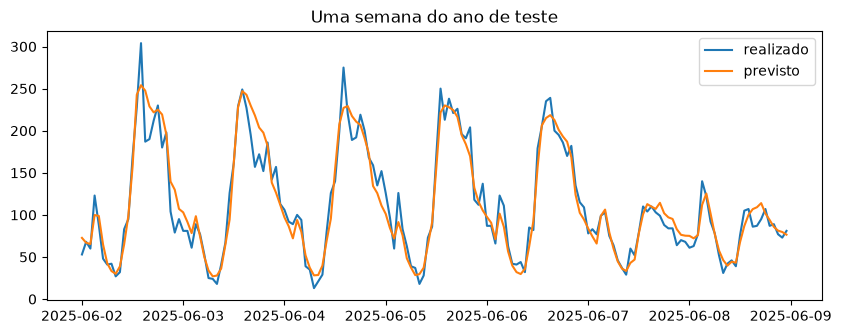

In [4]:
wk = cmp_.set_index('hour').loc['2025-06-02':'2025-06-08']
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(wk.index, wk['actual'], label='realizado'); ax.plot(wk.index, wk['forecast'], label='previsto')
ax.set_title('Uma semana do ano de teste'); ax.legend(); plt.show()

## 3. Quantas pessoas: dois cenários de meta de serviço
Pessoas presentes (Erlang C) e escaladas (com a folga fictícia).

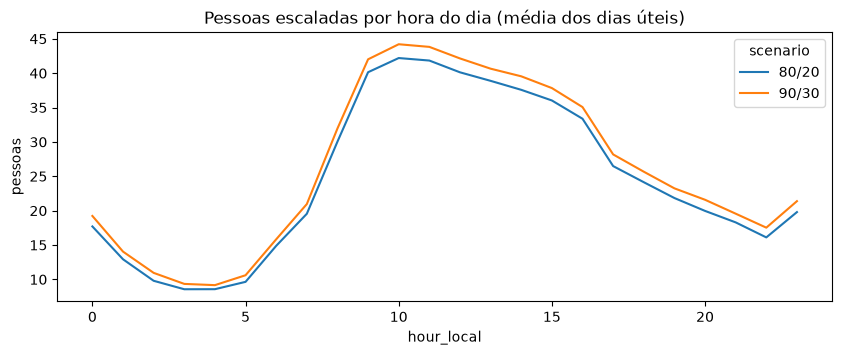

,scenario,agent_hours_present,agent_hours_scheduled,peak_present,peak_scheduled
0,80/20,135685,197442,35,50
1,90/30,144638,210309,36,52


In [5]:
p = plan.copy(); p['hour_local'] = p['hour'].dt.tz_convert(TZ)
wd = p[p['hour_local'].dt.day_of_week < 5].groupby(['scenario', p['hour_local'].dt.hour])['agents_scheduled'].mean().unstack(0)
wd.plot(figsize=(10, 3.5), title='Pessoas escaladas por hora do dia (média dos dias úteis)'); plt.ylabel('pessoas'); plt.show()
pd.DataFrame(R['staffing'])

## 4. Simulação de filas × Erlang C
Com atendimento exponencial a simulação confirma o Erlang C; com atendimento irregular (lognormal) o nível de serviço real fica um pouco abaixo.

In [6]:
pd.DataFrame(R['simulation']['casos'])[['hora','cenario','chamadas_hora_prevista','agentes_presentes','erlang','sim_exp','sim_lognormal','diff_exp','diff_lognormal']]

,hora,cenario,chamadas_hora_prevista,agentes_presentes,erlang,sim_exp,sim_lognormal,diff_exp,diff_lognormal
0,pico,80/20,290.3,35,0.850946,0.850722,0.843514,0.000224,0.007432
1,pico,90/30,290.3,36,0.915379,0.916236,0.906953,0.000857,0.008427
2,mediana,80/20,99.0,14,0.869803,0.870206,0.865925,0.000402,0.003878
3,mediana,90/30,99.0,15,0.937838,0.938475,0.935125,0.000637,0.002713
4,vale,80/20,38.1,7,0.907526,0.907642,0.906125,0.000116,0.001401
5,vale,90/30,38.1,7,0.915362,0.915236,0.914144,0.000126,0.001218


## 5. Monitoramento intraday
Horas cujo desvio relativo passa do limite (com piso de chamadas previstas).

{'limite_desvio': 0.3, 'horas_comparadas': 8760, 'horas_em_alerta': 2051, 'dia_com_mais_alertas': '2025-11-11', 'replay_dia': {'alerts': 22, 'sent': 0}, 'webhook_configurado': False}
[TESTE] Desvio em 2025-01-01 05:00:00+00:00: previsto 59, realizado 159 (+172%)


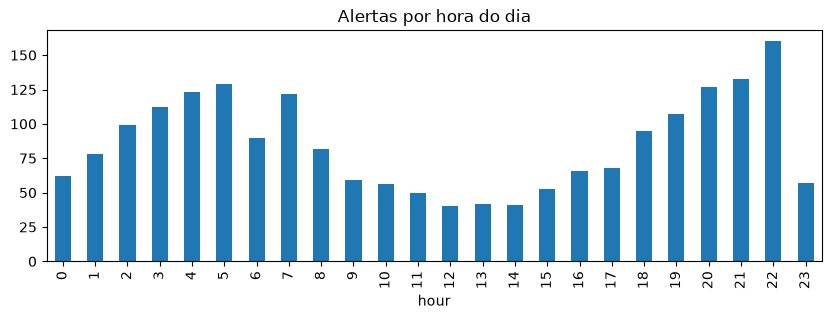

In [7]:
from src.monitor import find_alerts, format_alert
al = find_alerts(cmp_, R['monitor']['limite_desvio'])
al.groupby(al['hour'].dt.tz_convert(TZ).dt.hour).size().plot.bar(figsize=(10, 3), title='Alertas por hora do dia')
print(R['monitor']); print(format_alert(al.iloc[0]))

## 6. Analisador de entrada: tempo de atendimento real (Technion)
Nove distribuições ajustadas aos tempos reais de atendimento e ranqueadas por **AIC** (critério fixado antes de rodar). Mostro também BIC, a estatística KS e o erro quadrático. Com centenas de milhares de pontos, qualquer teste de aderência rejeita todas as candidatas, então o p-valor não é usado para decidir.

In [8]:
an = R['analisador']['atendimento_technion']
print('atendimentos reais:', an['n_total'], '| usados no ajuste:', an['n_usado'], '| limpeza:', an['limpeza'])
pd.DataFrame(an['ranking'])[['rank', 'name', 'aic', 'bic', 'ks_stat', 'sq_error']]

atendimentos reais: 351893 | usados no ajuste: 100000 | limpeza: {'kept': 351893, 'dropped_empty': 0, 'dropped_non_numeric': 0, 'dropped_nonpositive': 1250}


,rank,name,aic,bic,ks_stat,sq_error
0,1,weibull,1.251181e+06,1.251200e+06,0.068112,0.000082
1,2,gamma,1.251957e+06,1.251976e+06,0.066139,0.000100
2,3,expon,1.252014e+06,1.252023e+06,0.068521,0.000102
3,4,erlang,1.252016e+06,1.252035e+06,0.068521,0.000102
4,5,beta,1.253910e+06,1.253948e+06,0.070291,0.000116
5,6,lognormal,1.255886e+06,1.255905e+06,0.076633,0.000011
6,7,normal,1.403461e+06,1.403480e+06,0.239073,0.003545
7,8,triangular,1.796555e+06,1.796584e+06,0.874833,0.010101
8,9,uniform,1.932691e+06,1.932710e+06,0.921436,0.010542


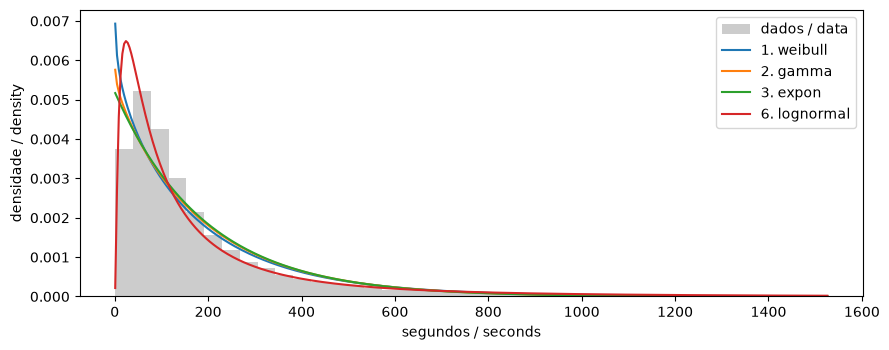

In [9]:
from app import logic
from src.distributions import DistSpec
d = logic.load_defaults(ROOT)
top = [(f"{x['rank']}. {x['name']}", DistSpec(x['name'], x['params'])) for x in d['fits'][:3]]
lg = next(x for x in d['fits'] if x['name'] == 'lognormal')
top.append((f"{lg['rank']}. lognormal", DistSpec('lognormal', lg['params'])))
logic.plot_fits(d['service_values'], top)

**Como ler.** O AIC e o erro quadrático não escolhem a mesma distribuição. A figura mostra por quê: os tempos reais têm um pico antes de 100 s, e a lognormal acompanha essa subida, enquanto a exponencial e a Weibull começam no máximo em zero. A exponencial (hipótese do Erlang C) fica próxima das melhores pelo AIC. A distribuição **proposta** é a de melhor AIC, regra definida antes de ver o resultado; o app permite testar outra.

### Chegadas do NYC 311: intervalos entre chamadas, por faixa de hora

In [10]:
pd.DataFrame(R['analisador']['chegadas_nyc'])[['faixa', 'n_total', 'n_usado', 'melhor']]

,faixa,n_total,n_usado,melhor
0,0-6h,148438,100000,gamma
1,9-17h,912893,100000,beta
2,18-24h,310014,100000,beta


Cada faixa mistura horas com taxas diferentes, então intervalos que não são exponenciais são esperados; isso, sozinho, não refuta chegadas de Poisson.

## 7. Validação contra o banco real
Repete as chegadas reais do banco (dias úteis, numa hora do dia) com a distribuição proposta e compara a espera simulada com a real.

In [11]:
pd.Series(R['validacao_banco'])

n_calls                                                                    27624
n_days                                                                       251
real_mean_wait_s                                                       89.187337
sim_mean_wait_s                                                        41.148405
real_service_level                                                      0.373769
sim_service_level                                                       0.730959
abandoned_share                                                         0.228078
agentes                                                                        8
meta_espera_s                                                                 20
hora                                                                          10
dias                                      dias úteis do banco (domingo a quinta)
ressalva                       O banco real tem abandono de fila e o simulado...
varredura                   

**Como ler.** A simulação não reproduz a espera real do banco. O motivo não está demonstrado: o simulador não modela abandono, pausas nem pós-atendimento, usa o número de posições da documentação e começa com a fila vazia no início da janela, o que o deixa mais otimista. O resultado é reportado como saiu.

A tabela abaixo repete a simulação com outros números de agentes. É uma **calibração**: o número que mais se aproxima não é a quantidade de pessoas que havia no banco nem prova que o modelo está certo.

In [12]:
pd.DataFrame(R['validacao_banco']['varredura'])

,agentes,sim_mean_wait_s,sim_service_level
0,4,947.627844,0.107805
1,5,479.704737,0.207790
2,6,228.058813,0.377353
3,7,101.127150,0.566102
4,8,41.148405,0.730959
5,9,15.669632,0.851940
6,10,5.975442,0.925862
7,11,2.323844,0.966116
8,12,0.899214,0.985737


## 8. Aviso ao autor da base (Technion SEE Center)

Os termos de uso da base *Anonymous Bank* pedem que quem a usar avise o professor Avi Mandelbaum e cite a fonte. O aviso foi enviado em **25/11/2026**.

- **Para:** avim@ie.technion.ac.il (endereço público na página da base)
- **Cc:** see@technion.ac.il (equipe SEE, também citada na página)
- **Assunto:** Notice of use: Anonymous Bank call-center data (SEE Center)

Texto enviado:

> Dear Professor Mandelbaum,
>
> My name is Sérgio Salles, and I am a data analyst based in Brazil. In line with the terms on the SEE Center data page, I am writing to let you know that I am using the "Anonymous Bank" call-center data (1999, documented by Ilan Guedj and yourself) in a personal portfolio project.
>
> The project is a workforce-management study: it forecasts hourly demand, sizes a team with Erlang C, and compares the result with a discrete-event queue simulation. I use your data for two things only: (1) fitting probability distributions to the real service times, in the spirit of the Arena Input Analyzer, and (2) checking my simulator against the waiting times the bank's call center actually had. Arrivals in the main scenario come from a different public dataset, NYC 311, and the project says so explicitly.
>
> The source is acknowledged in the README and in a FONTES.md file as "Anonymous Bank" call-center data, SEE Center, Technion, documentation by I. Guedj and A. Mandelbaum (2000). The code is public at github.com/safsalles/portfolio-ds. So that the project runs without any download, the repository will include a small derived extract of the data (service times and basic call fields, not the original files). If you would prefer that I not redistribute any extract, please tell me and I will remove it and point to your site instead.
>
> Thank you very much for making the data freely available. I would be glad to share the results if they are of interest.
>
> Kind regards,
> Sérgio Salles
> github.com/safsalles

*Por privacidade, o endereço do remetente e o identificador da mensagem não foram reproduzidos aqui. Até esta data não houve resposta registrada; se o professor pedir para não redistribuir o extrato, ele será removido do repositório.*

## 9. Conclusões e limites
- O modelo reajustado praticamente empata com a regra simples; o ajuste único perde por mudança de nível do volume.
- O Erlang C bate com a simulação sob as suas hipóteses.
- O horário de abertura do chamado é tomado como horário de chegada; a equipe e os tempos são fictícios.